In [92]:
import re
import mne
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import COL_W, TEXT_W

from pathlib import Path
from datetime import datetime

# Prepare and filter data

In [93]:
def get_sfreq(filepath: str) -> float:
    """Read an MNE-style EEG info file and return the sampling frequency."""
    with open(filepath, 'r') as f:
        content = f.read()

    match = re.search(r'Info:\s*(\{.*\})', content, re.DOTALL)
    if not match:
        raise ValueError("Info block not found in file")

    info = json.loads(match.group(1))
    return float(info['sfreq'])

def expand_json_column(csv_path):
    df = pd.read_csv(csv_path)
    def parse(val):
        try:
            # Strip ['...'] wrapper and unescape ""
            inner = val.strip()[2:-2].replace('""', '"')
            d = json.loads(inner)
            payload = d.pop("Payload", {}) or {}
            # Flatten nested dicts in payload (e.g. Position: {x, y, z})
            for k, v in list(payload.items()):
                if isinstance(v, dict):
                    payload.update({f"{k}_{sk}": sv for sk, sv in v.items()})
                    del payload[k]
            return {**d, **payload}
        except (json.JSONDecodeError, TypeError):
            return {"raw": val.strip()[2:-2]}

    return df.iloc[:, :-1].join(df.iloc[:, -1].apply(parse).apply(pd.Series))

def load_data(ts, subject_id, data_folder = 'data', ref_ch = "Cz"):
    markers = expand_json_column(f'{data_folder}/subject_{subject_id}/markers_{ts}.csv')
    markers["idx"] = [i for i in range(len(markers))]
    eeg = pd.read_csv(f'{data_folder}/subject_{subject_id}/eeg_Experiment.VIBE.EEG_{ts}.csv')
    gaze = pd.read_csv(f'{data_folder}/subject_{subject_id}/gaze_Experiment.VIBE.ViveOpenXR_Gaze_{ts}.csv')

    eeg_freq = get_sfreq(f'{data_folder}/subject_{subject_id}/eeg_Experiment.VIBE.EEG_{ts}_metadata.txt')
    eeg.timestamp = [t/eeg_freq for t in range(0, len(eeg.timestamp))] + eeg.timestamp[0]

    return markers, eeg, gaze, eeg_freq

def get_stimulus_markers(markers):
    # return markers[(markers.value.str.contains('BLINK_END'))]
    return markers[(markers.stream == 'Experiment.VIBE.GameEventStream') & (markers['EventName']=='PINCH_STIMULUS')]

def load_marker_eeg_windows(markers, eeg, eeg_freq, window_start_ms=-1000, window_end_ms=500):
    """
    window_start: window start offset relative to the current marker
    window_end: window end offset relative to the current marker
    """
    pre_samples = int((window_start_ms / 1000) * eeg_freq)
    post_samples = int((window_end_ms / 1000) * eeg_freq)
    n_samples    = -pre_samples + post_samples + 1
    time_rel_ms  = np.linspace(window_start_ms, window_end_ms, n_samples)


    timestamps = eeg['timestamp'].to_numpy()
    channel_cols = [c for c in eeg.columns if c != 'timestamp']

    windows = []
    for index, marker_ts in zip(markers.idx, markers.timestamp):
        # Find the sample closest to the marker timestamp
        idx = np.argmin(np.abs(timestamps - marker_ts))
        start = idx + pre_samples
        end = start + n_samples

        if start < 0 or end > len(eeg):
            print(f"Skipping marker {marker_ts}: window out of bounds.")
            continue

        window = eeg.iloc[start:end][channel_cols].copy()
        window.insert(0, "marker_timestamp", marker_ts)
        window.insert(1, "marker_index", index)
        window.insert(2, "sample_index", range(start, end))
        window.insert(3, "time_rel_ms", time_rel_ms)
        windows.append(window)

    return pd.concat(windows, ignore_index=True)

In [115]:
BASELINE_CORRECTION = False   # subtract per-epoch mean from every channel
COLS_TO_SKIP = {"marker_timestamp", "marker_index", "sample_index", "time_rel_ms", "X1", "X2", "X3", "TRG"}
N_COLS = 4                    # subplot columns in the figure
COLOR = "#378ADD"

def plot_epochs(
    epochs: pd.DataFrame,
    baseline_correction: bool = False,
    plot_mean: bool = False,
    high_activation_filter = None,
    n_cols: int = 4,
    figsize_per_ax: tuple[float, float] = (TEXT_W / 4, 1.3),
    title: str = "EEG epochs",
) -> plt.Figure:
    channel_cols = sorted([c for c in epochs.columns if c not in COLS_TO_SKIP])
    markers      = sorted(epochs["marker_index"].unique())

    alpha = max(10/len(markers), 0.02)
    markersize = min(alpha*10, 1)

    n_axes = len(channel_cols)
    n_rows = int(np.ceil(n_axes / n_cols))
    fig_w  = TEXT_W  # always the full text width, whatever n_cols
    fig_h  = figsize_per_ax[1] * n_rows + 0.3   # extra for the suptitle

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(fig_w, fig_h),
        sharex=True,
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()

    for ax_idx, ch in enumerate(channel_cols):
        ax = axes_flat[ax_idx]

        if plot_mean:
            all_y = []
            for mt in markers:
                mask = epochs["marker_index"] == mt
                subset = epochs.loc[mask].sort_values("time_rel_ms")
                y = subset[ch].to_numpy(dtype=float)
                if high_activation_filter is not None and (np.abs(y) > high_activation_filter).any():
                    continue
                if baseline_correction:
                    y = y - y[0]
                all_y.append(y)

            if len(all_y) == 0:
                continue
            mean_y = np.mean(all_y, axis=0)
            t = epochs.loc[epochs["marker_index"] == markers[0]].sort_values("time_rel_ms")["time_rel_ms"].to_numpy()

            ax.plot(t, mean_y, color="black", linewidth=1, label="mean", zorder=5)

        else:
            for mi, mt in enumerate(markers):
                mask   = epochs["marker_index"] == mt
                subset = epochs.loc[mask].sort_values("time_rel_ms")
                t      = subset["time_rel_ms"].to_numpy()
                y      = subset[ch].to_numpy(dtype=float)

                if high_activation_filter is not None and (np.abs(y) > high_activation_filter).any():
                    continue

                if baseline_correction:
                    y = y - y[0]

                ax.plot(t, y, color=COLOR, marker='o', linestyle='None', markersize=markersize, alpha=alpha)

        # zero-time marker
        ax.axvline(0, color="gray", linewidth=0.6, linestyle=":", zorder=0)
        ax.axhline(0, color="gray", linewidth=0.4, linestyle="-", zorder=0, alpha=0.4)

        ax.set_title(ch, pad=3)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(4))
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

    # hide unused axes
    for ax in axes_flat[n_axes:]:
        ax.set_visible(False)

    # shared x-label on the bottom row
    for ax in axes_flat[(n_rows - 1) * n_cols : n_axes]:
        ax.set_xlabel("Time (ms)")

    handles, labels = axes_flat[0].get_legend_handles_labels()

    bc_tag = " (baseline corrected)" if baseline_correction else ""
    fig.suptitle(title + bc_tag)
    plt.close(fig)

    return fig

def get_ts(subject_id, measurement_index):
    pattern = re.compile(r"(\d{8}_\d{6})")

    timestamps = set()
    for path in Path(f'data/subject_{subject_id}').iterdir():
        match = pattern.search(path.name)
        if match:
            timestamps.add(match.group(1))

    return sorted(timestamps)[measurement_index]


def filter_by_experiment(markers, experiments):
    """
    returns stimuli selection markers that belong to one of the experiments.
    """
    return markers[markers.EventName.isin(experiments) & markers.Message.str.contains("target")]

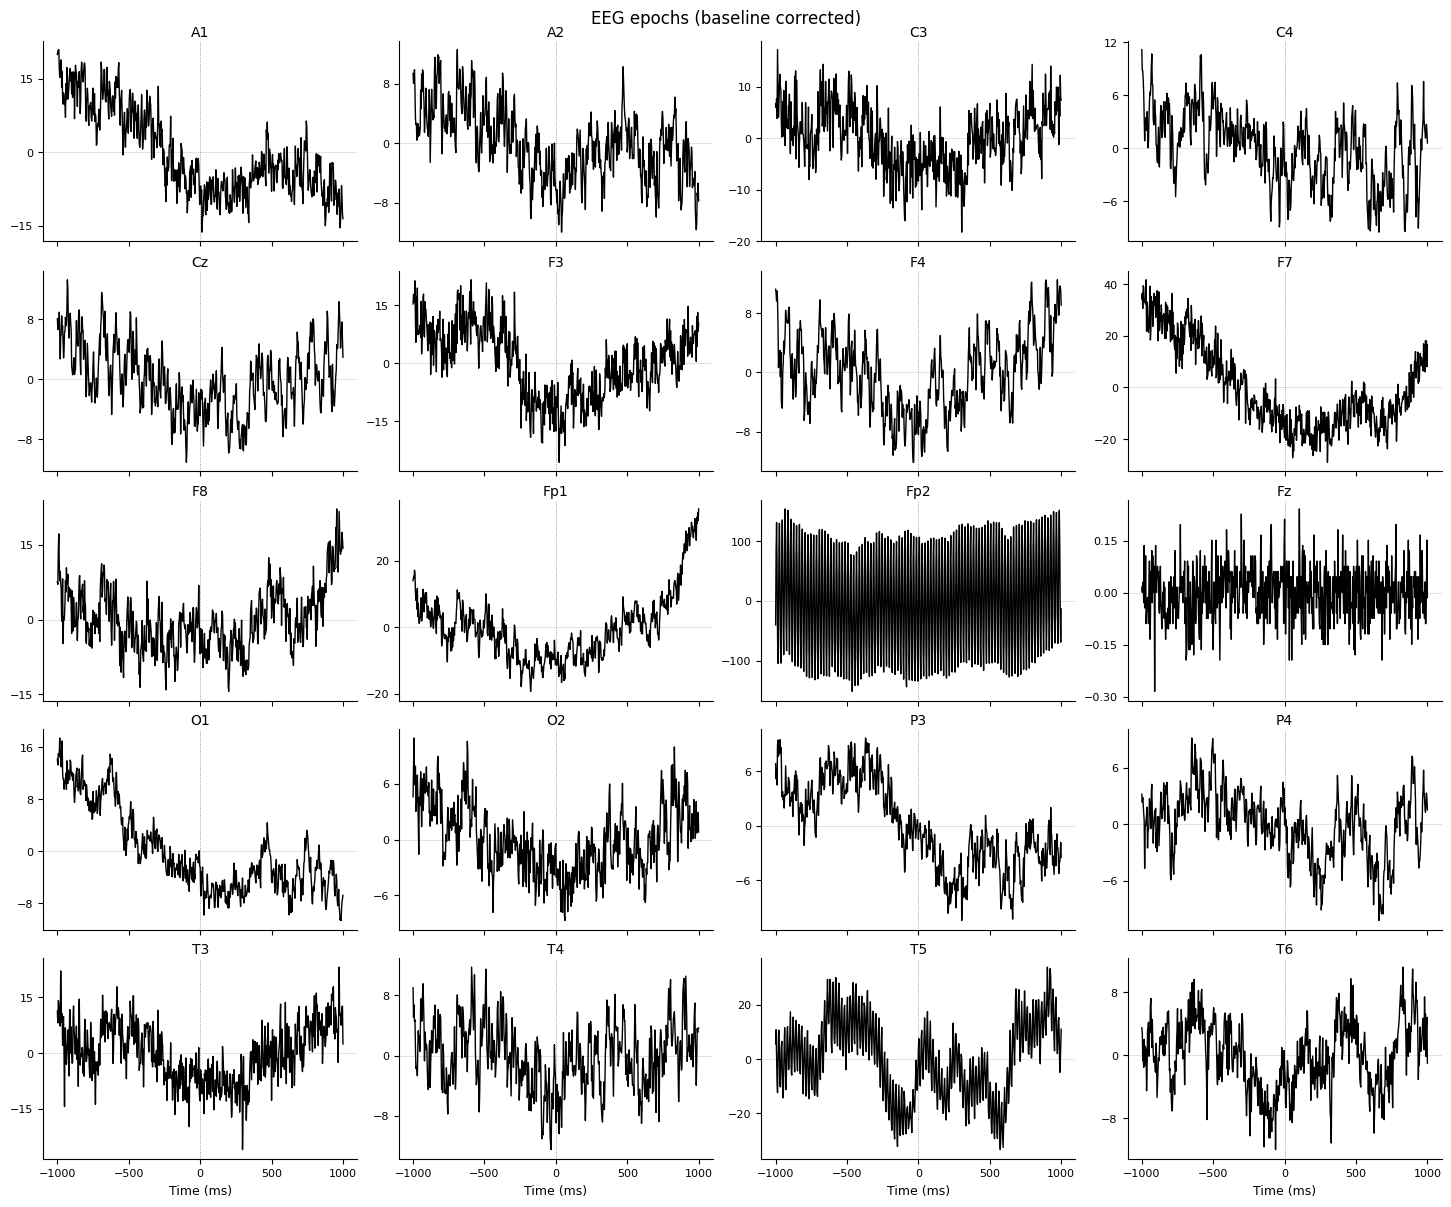

In [95]:
SUBJECT = '7'
TS = get_ts(SUBJECT, 0)

markers, eeg, gaze, eeg_freq = load_data(TS, SUBJECT)
markers = filter_by_experiment(markers, ["Static"])
stimulus_markers = markers
marker_eegs = load_marker_eeg_windows(stimulus_markers, eeg, eeg_freq, window_end_ms=1000)
plot_epochs(marker_eegs, baseline_correction=True, plot_mean=True)

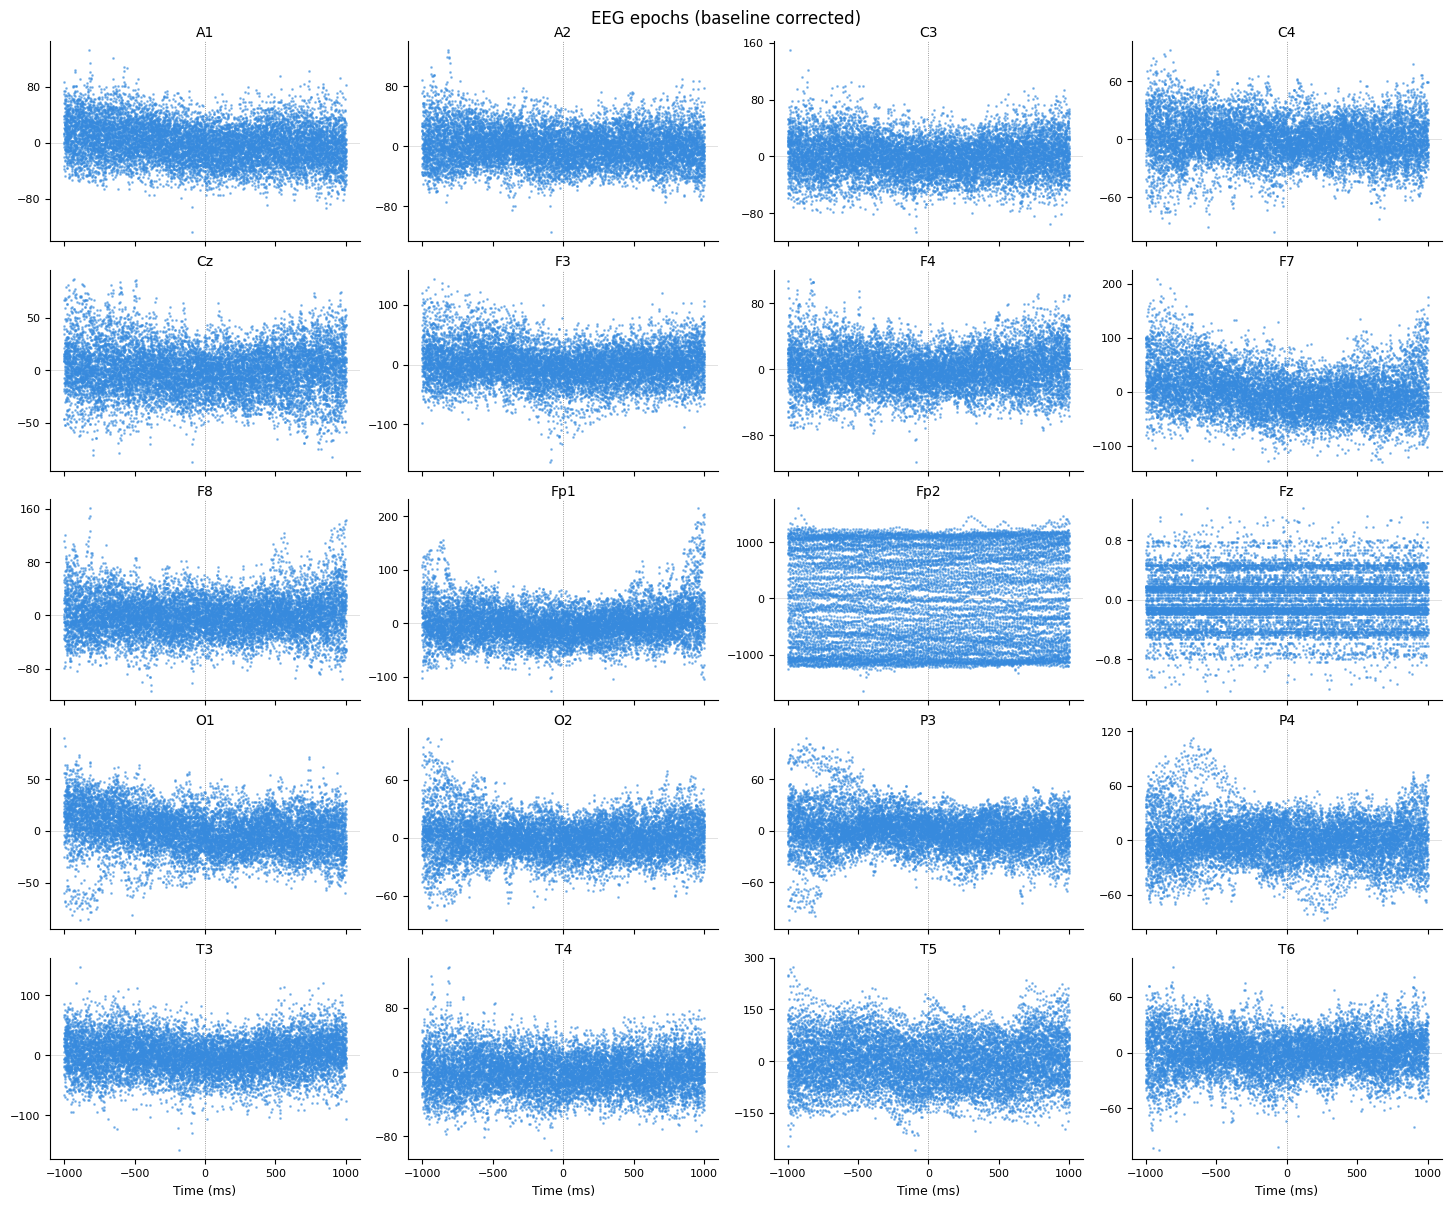

In [110]:
plot_epochs(marker_eegs, baseline_correction=True)

## Raw Signal Visualization

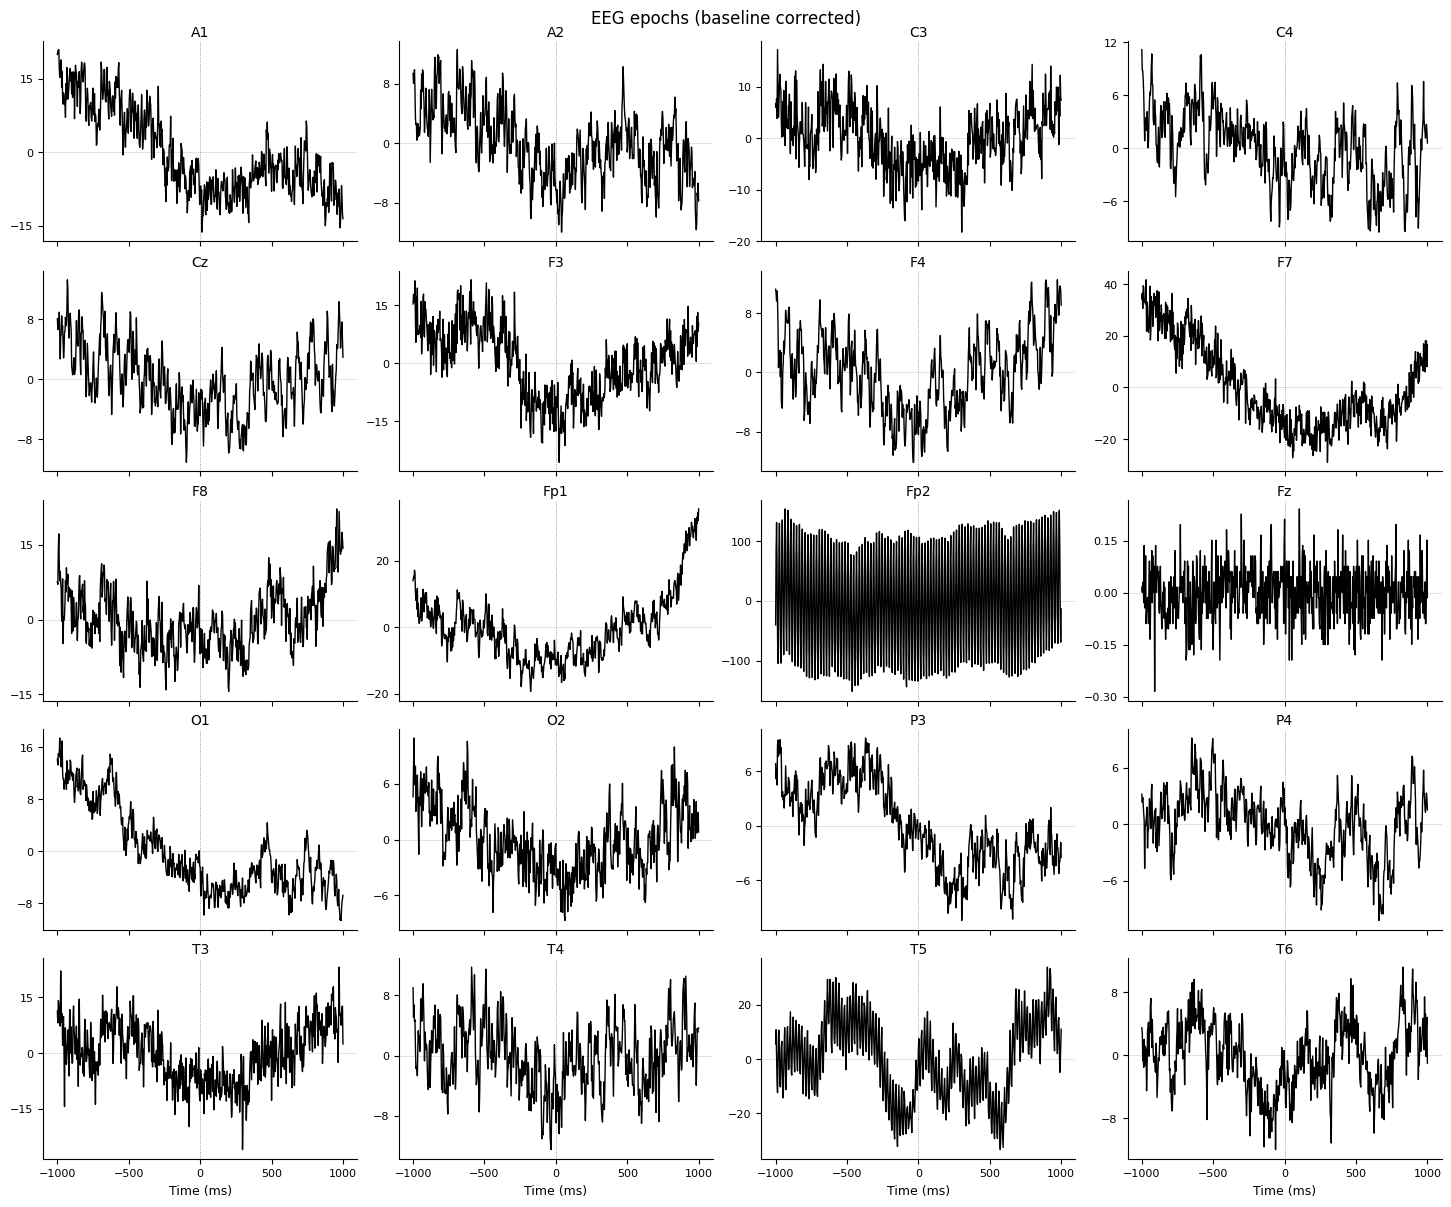

In [97]:
plot_epochs(marker_eegs, baseline_correction=True, plot_mean=True)

In [98]:
(eeg.timestamp[len(eeg.timestamp)-1] - eeg.timestamp[0])/60

np.float64(27.867222222222228)

# Post-processing and visualization

- Notch filter (50Hz)
- Low-Pass filter (100Hz)
- High-Pass filter (1Hz)

In [99]:
def filter_eeg(df: pd.DataFrame, sfreq: float = 300.0, highpass: float = 1.0,
               lowpass: float = 100.0, notch: float = 50.0) -> pd.DataFrame:
    """
    df      : DataFrame with shape (n_samples, n_channels), one electrode per column.
    sfreq   : Sampling frequency in Hz (DSI-24 default: 300 Hz).
    highpass: High-pass cutoff in Hz (removes DC drift / slow baseline).
    lowpass : Low-pass cutoff in Hz (removes EMG and high-freq noise).
    notch   : Line noise frequency in Hz.
    """
    # --- build MNE RawArray ---
        # --- separate timestamps from EEG data ---
    timestamps = df["timestamp"]
    df = df.drop(columns=["timestamp"])

    ch_names = df.columns.tolist()
    info = mne.create_info(
        ch_names=ch_names,
        sfreq=sfreq,
        ch_types="eeg"
    )

    # convert ﷿﷿﷿﷿﷿﷿V to volts (DSI-24 output to MNE input)
    data = df.values.T * 1e-6
    raw = mne.io.RawArray(data, info, verbose=False)
    mne.set_log_level("WARNING")       # suppress verbose output

    # --- 1. Notch filter (line noise) ---
    raw.notch_filter(freqs=notch, verbose=False)

    # --- 2. Band-pass (high-pass + low-pass in one call) ---
    raw.filter(l_freq=highpass, h_freq=lowpass,
               method="fir",
               fir_window="hamming",
               verbose=False)

    # --- back to DataFrame (﷿﷿﷿﷿﷿﷿V) ---
    filtered = raw.get_data() * 1e6   # back to ﷿﷿﷿﷿﷿﷿V, shape (n_ch, n_samples)
    filtered_df = pd.DataFrame(filtered.T, index=df.index, columns=df.columns)
    filtered_df.insert(0, "timestamp", timestamps)
    return filtered_df

In [100]:
filtered_eeg = filter_eeg(eeg, sfreq=eeg_freq)
filtered_marker_eegs = load_marker_eeg_windows(stimulus_markers, filtered_eeg, eeg_freq, window_end_ms=1000)

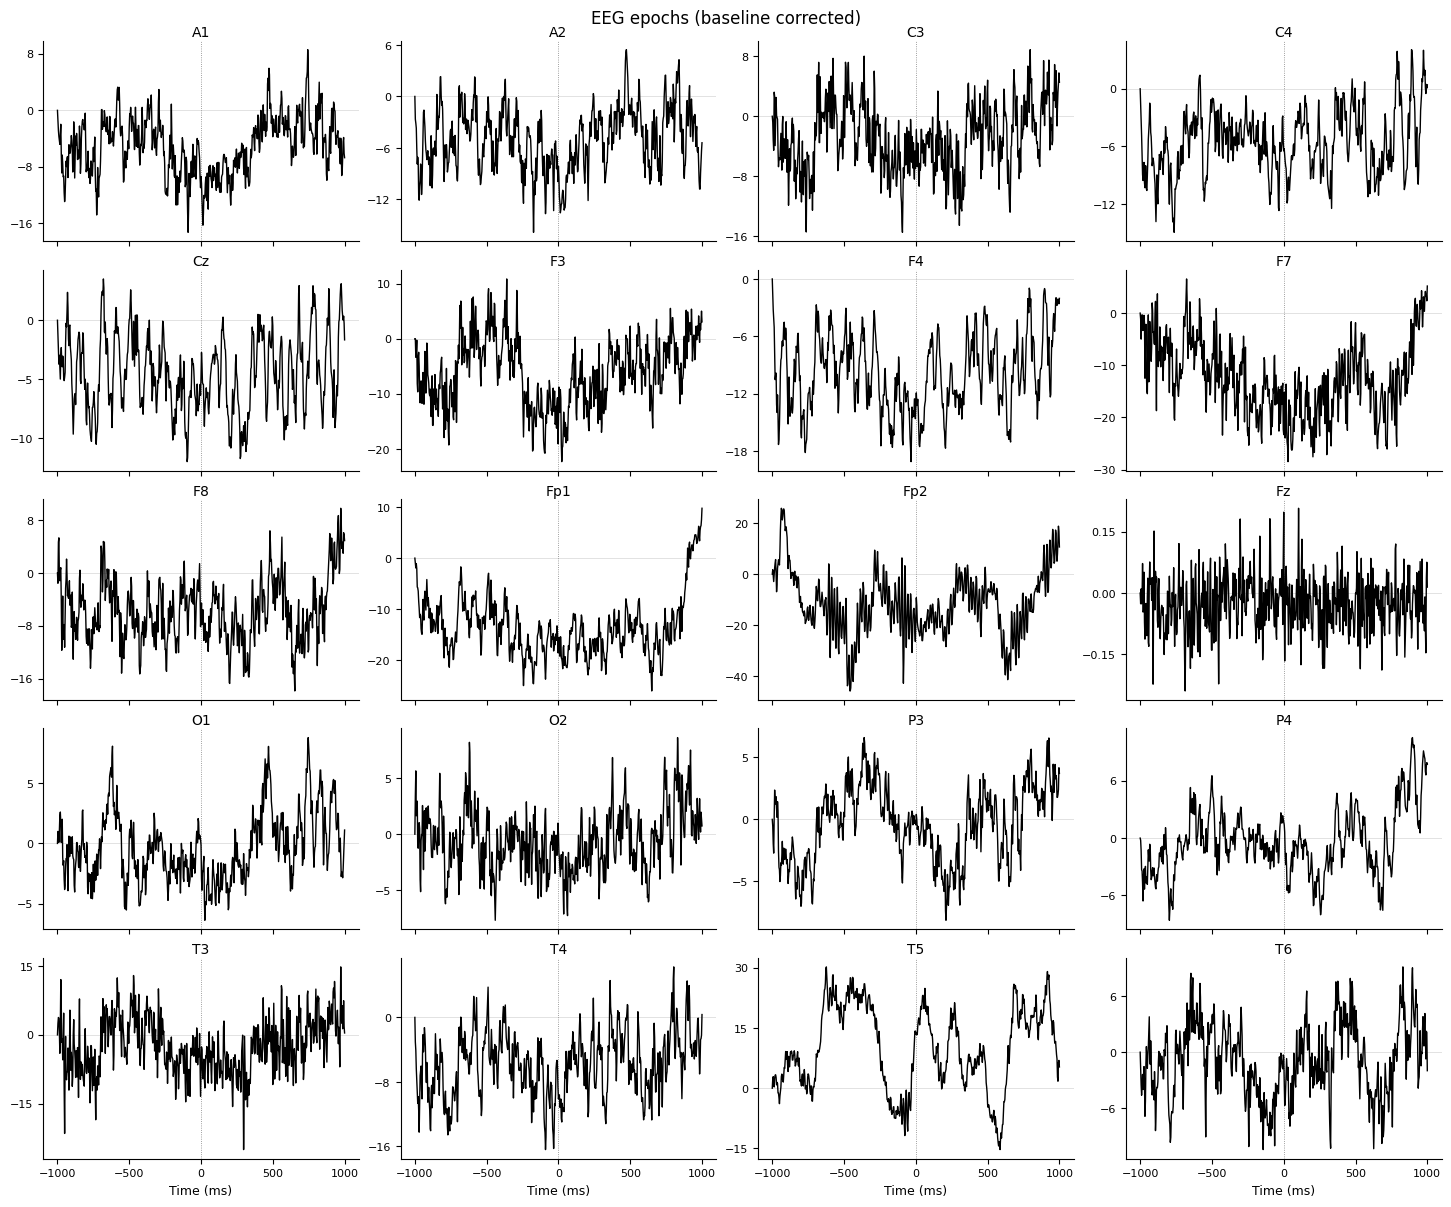

In [116]:
plot_epochs(filtered_marker_eegs, baseline_correction=True, plot_mean=True)

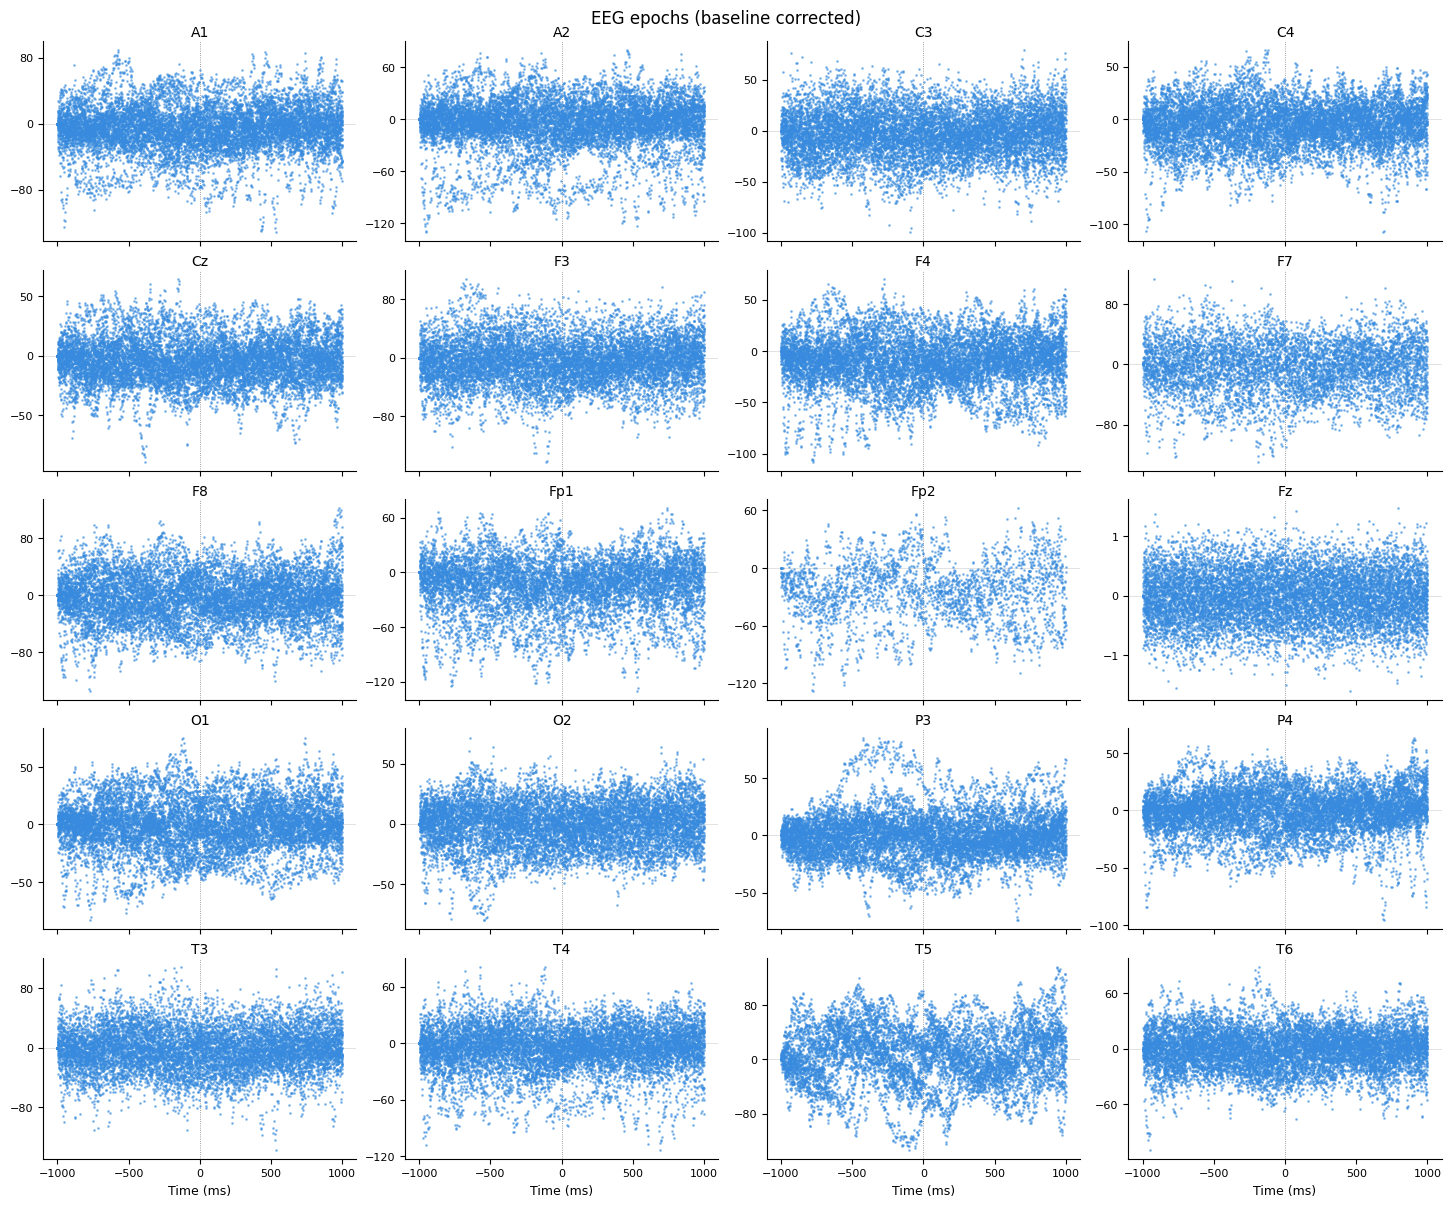

In [118]:
plot_epochs(filtered_marker_eegs, baseline_correction=True, high_activation_filter=100)

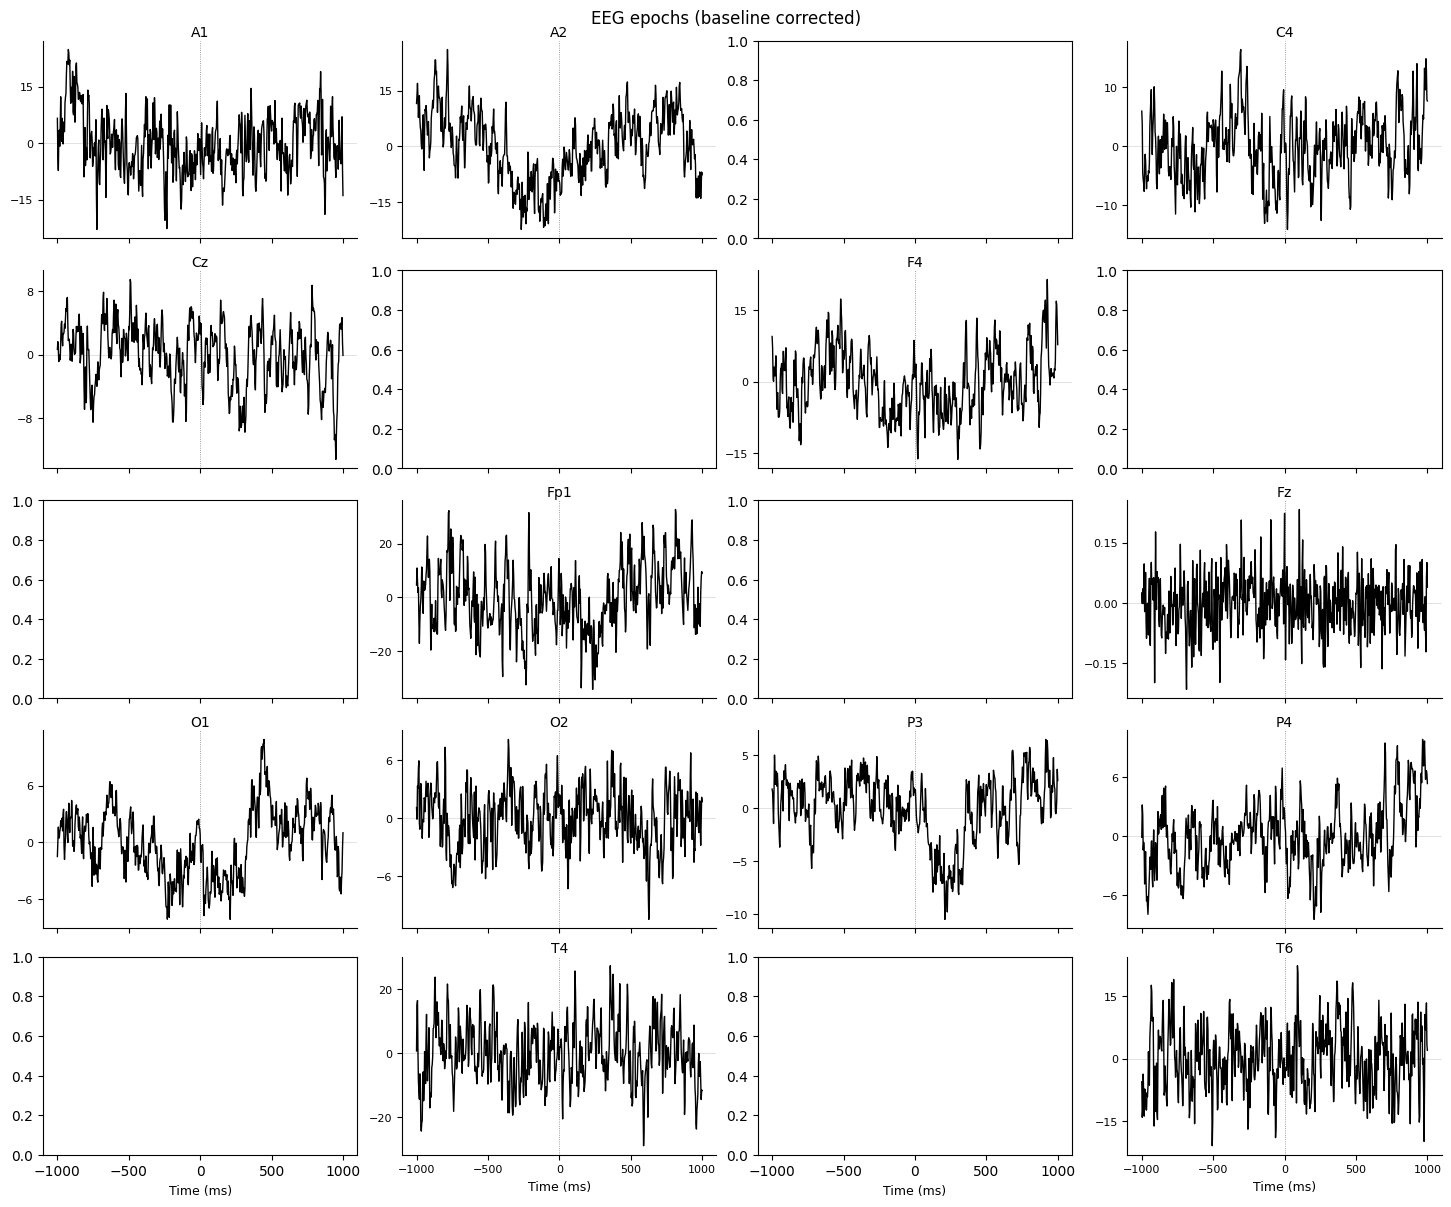

In [103]:
plot_epochs(filtered_marker_eegs, baseline_correction=True, plot_mean=True, high_activation_filter=40)

In [104]:
marker_eegs

,marker_timestamp,marker_index,sample_index,time_rel_ms,P3,C3,F3,Fz,F4,C4,...,O2,X3,X2,F7,F8,X1,A2,T6,T4,TRG
0,7425.001849,119,22882,-1000.000000,227.556000,-919.033264,-812.267212,-35.559189,-819.792664,-208.650299,...,-465.516418,-9.933,-5.719,529.248962,265.091980,-8.428,165.440628,-392.335419,-466.091370,0.0
1,7425.001849,119,22883,-996.666667,230.867004,-901.499084,-793.524902,-36.161888,-807.430969,-205.639465,...,-463.408630,-10.234,-5.418,558.735229,275.623444,-8.428,181.110779,-389.919189,-468.808228,0.0
2,7425.001849,119,22884,-993.333333,237.188004,-890.615784,-782.339966,-36.161888,-787.230103,-197.510239,...,-463.408630,-10.535,-6.020,582.805664,307.518738,-8.428,200.397125,-418.611938,-452.205231,0.0
3,7425.001849,119,22885,-990.000000,246.218002,-861.291382,-749.389771,-36.161888,-761.300659,-175.531204,...,-462.806427,-10.234,-6.321,611.389343,321.961884,-8.127,207.328156,-418.913971,-418.697357,0.0
4,7425.001849,119,22886,-986.666667,239.595993,-868.244568,-757.249451,-36.463238,-769.441345,-183.058258,...,-462.806427,-9.933,-5.719,605.070862,308.120544,-8.428,200.698471,-413.175415,-422.923584,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12015,7520.850976,264,52233,986.666667,-185.115005,-1212.882080,-1233.062134,-36.161888,-973.258850,-918.302124,...,-634.138123,-10.234,-5.719,-774.466614,13.841352,-8.428,-328.470490,-433.411346,-879.053162,0.0
12016,7520.850976,264,52234,990.000000,-181.503006,-1205.324219,-1221.574829,-36.463238,-965.721191,-918.603210,...,-625.104858,-9.933,-5.719,-773.263123,38.515068,-8.729,-324.552948,-439.149902,-866.072632,0.0
12017,7520.850976,264,52235,993.333333,-188.425995,-1209.254272,-1213.715210,-36.161888,-970.846802,-918.904297,...,-631.127014,-10.535,-5.418,-771.457825,32.797985,-8.428,-329.374512,-436.733643,-878.147522,0.0
12018,7520.850976,264,52236,996.666667,-197.455994,-1223.160645,-1220.970337,-36.161888,-984.113037,-934.560608,...,-610.049316,-10.234,-5.719,-761.227905,11.735060,-8.127,-332.388000,-448.210754,-892.335571,0.0


In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def any_above_threshold(arr: np.ndarray, threshold: float):
    mask = np.abs(arr) > threshold
    return mask.any(), np.argwhere(mask)

def plot_eeg_fft(
    df: pd.DataFrame,
    sfreq: float = 300.0,
    n_markers: int | None = None,
    average_only: bool = False,
    artifact_threshold: float | None = None,
) -> None:
    meta_cols = {"marker_timestamp", "marker_index", "sample_index", "time_rel_ms", "X1", "X2", "X3", "TRG"}
    electrode_cols = [c for c in df.columns if c not in meta_cols]

    all_markers = sorted(df["marker_index"].unique())
    if n_markers is not None:
        all_markers = all_markers[:n_markers]
    df = df[df["marker_index"].isin(all_markers)]

    if artifact_threshold is not None:
        clean_mask = (
            df.groupby("marker_index")
              .apply(lambda w: not any_above_threshold(
                  w[electrode_cols].values, artifact_threshold))
        )
        clean_markers = clean_mask[clean_mask].index.tolist()
        n_excluded = len(all_markers) - len(clean_markers)
        if n_excluded:
            print(f"Excluded {n_excluded} window(s) exceeding "
                  f"|{artifact_threshold}| µV threshold.")
        df = df[df["marker_index"].isin(clean_markers)]

    markers = sorted(df["marker_index"].unique())
    if not markers:
        print("No windows remaining after artifact rejection.")
        return

    # --- compute freqs once from the first window ---
    n_samples = (df[df["marker_index"] == markers[0]]
                 .shape[0])
    freqs = np.fft.rfftfreq(n_samples, d=1.0 / sfreq)   # defined before all loops

    # --- pre-compute FFT per marker per electrode ---
    spectra = {}
    for marker in markers:
        window = (df[df["marker_index"] == marker]
                  .sort_values("sample_index"))
        eeg = window[electrode_cols].values
        spectra[marker] = {}
        for i, col in enumerate(electrode_cols):
            fft_vals = np.fft.rfft(eeg[:, i])
            spectra[marker][col] = (np.abs(fft_vals), np.angle(fft_vals))

    def _itpc(phases: np.ndarray) -> np.ndarray:
        return np.abs(np.mean(np.exp(1j * phases), axis=0))

    n_cols = len(markers)

    for col in electrode_cols:
        amps   = np.array([spectra[m][col][0] for m in markers])  # (n_markers, n_freqs)
        phases = np.array([spectra[m][col][1] for m in markers])  # (n_markers, n_freqs)
        itpc   = _itpc(phases)                                     # (n_freqs,)

        if average_only:
            fig, (ax_amp, ax_itpc) = plt.subplots(
                1, 2, figsize=(COL_W, 1.8),
                constrained_layout=True,
            )
            fig.suptitle(f"{col} — averaged over {len(markers)} windows")

            ax_amp.plot(freqs, amps.mean(axis=0), linewidth=1.0, color="steelblue")
            ax_amp.set_title("Mean amplitude")
            ax_amp.set_xlabel("Frequency (Hz)")
            ax_amp.set_ylabel("Amplitude (µV)")

            ax_itpc.plot(freqs, itpc, linewidth=1.0, color="darkorange")
            ax_itpc.set_title("Phase coherence")
            ax_itpc.set_xlabel("Frequency (Hz)")
            ax_itpc.set_ylabel("ITPC")
            ax_itpc.set_ylim(0, 1)
            ax_itpc.axhline(0.5, color="gray", linewidth=0.5, linestyle="--",
                            label="chance")
            ax_itpc.legend()

        else:
            fig, axes = plt.subplots(
                2, n_cols,
                figsize=(max(1.6 * n_cols, TEXT_W), 3.6),
                squeeze=False,
                constrained_layout=True,
            )
            fig.suptitle(col)

            for c_idx, marker in enumerate(markers):
                amp   = amps[c_idx]
                phase = phases[c_idx]

                ax_amp  = axes[0][c_idx]
                ax_itpc = axes[1][c_idx]

                # amplitude line + phase color overlay
                ax_amp.plot(freqs, amp, linewidth=0.8, color="steelblue", zorder=2)
                sc = ax_amp.scatter(freqs, amp, c=phase, cmap="hsv",
                                    vmin=-np.pi, vmax=np.pi, s=6, zorder=3)
                ax_amp.set_title(f"marker\n{marker}")
                ax_amp.set_xlabel("Frequency (Hz)")

                # ITPC (same across columns — overall coherence)
                ax_itpc.plot(freqs, itpc, linewidth=0.8, color="darkorange")
                ax_itpc.set_ylim(0, 1)
                ax_itpc.axhline(0.5, color="gray", linewidth=0.5, linestyle="--")
                ax_itpc.set_xlabel("Frequency (Hz)")

                if c_idx == 0:
                    ax_amp.set_ylabel("Amplitude (µV)")
                    ax_itpc.set_ylabel("ITPC")

            # shared colorbar for phase — constrained_layout handles spacing
            cbar = fig.colorbar(sc, ax=axes[0, :].tolist(),
                                orientation="vertical", pad=0.02,
                                label="Phase (rad)")
            cbar.set_ticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
            cbar.set_ticklabels(["-π", "-π/2", "0", "π/2", "π"])

        plt.show()

<Axes: >

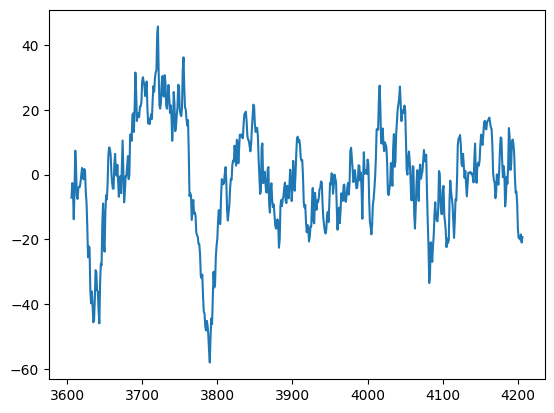

In [106]:
i=6
filtered_marker_eegs[filtered_marker_eegs.marker_index == filtered_marker_eegs.marker_index.unique()[i]].O1.plot()

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


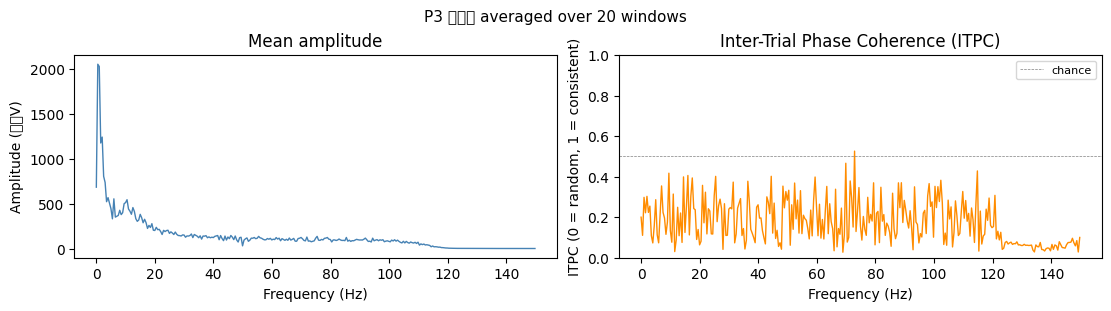

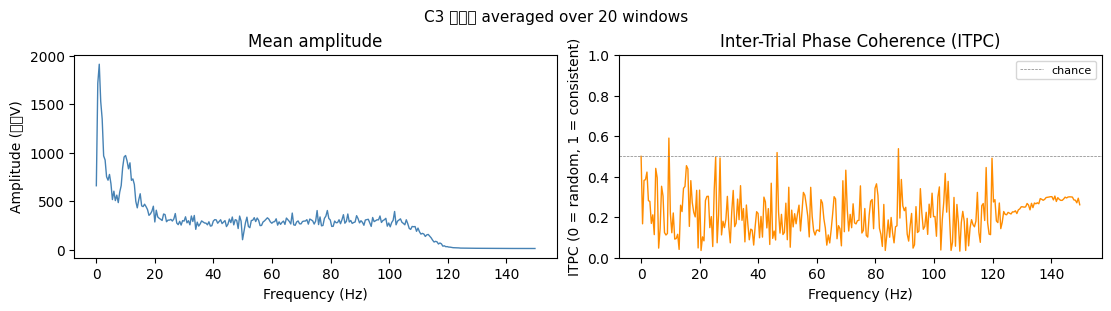

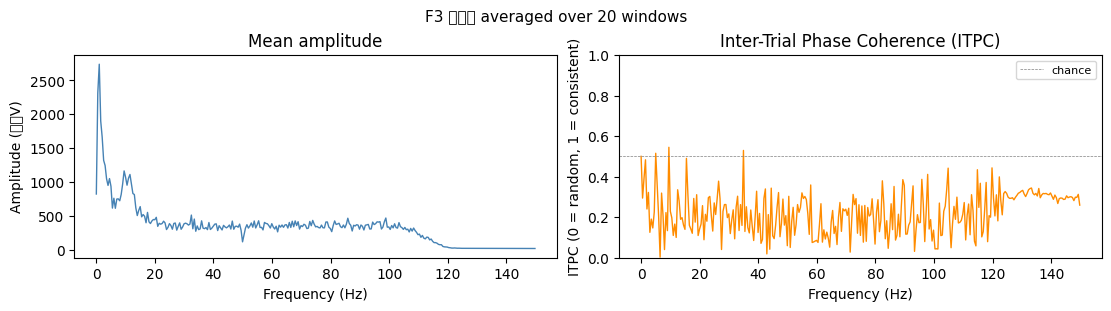

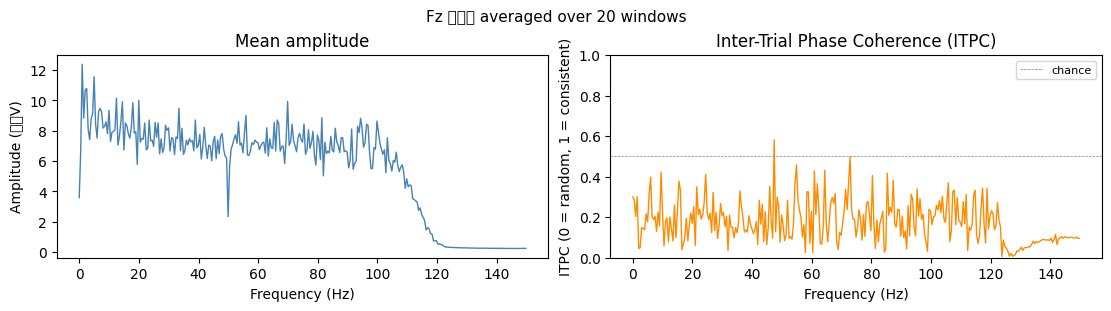

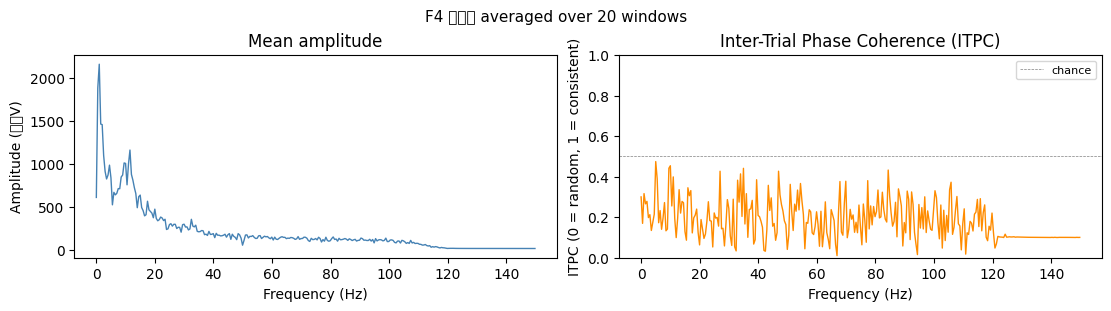

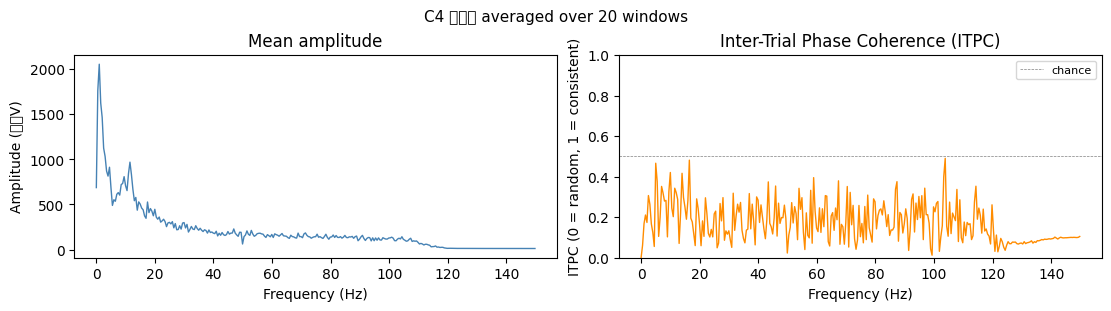

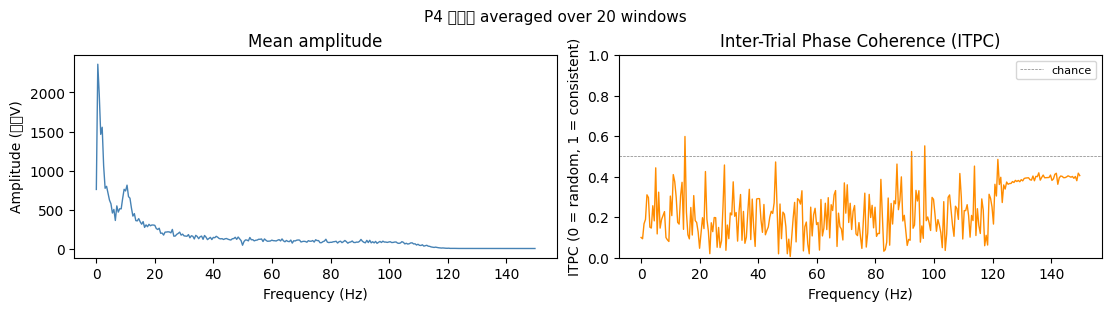

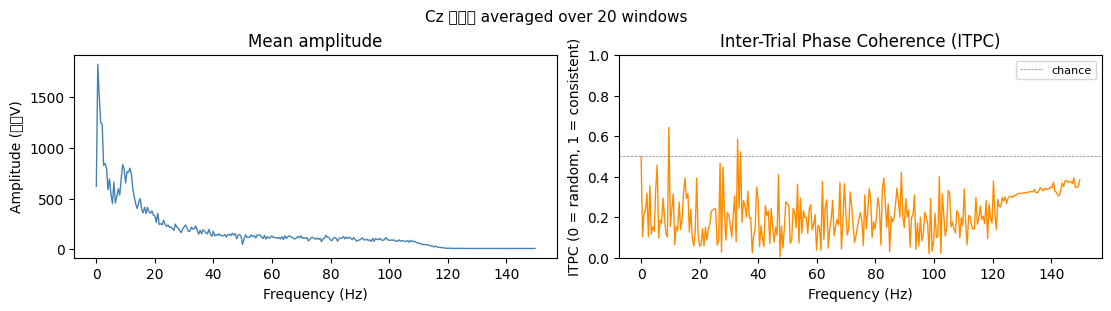

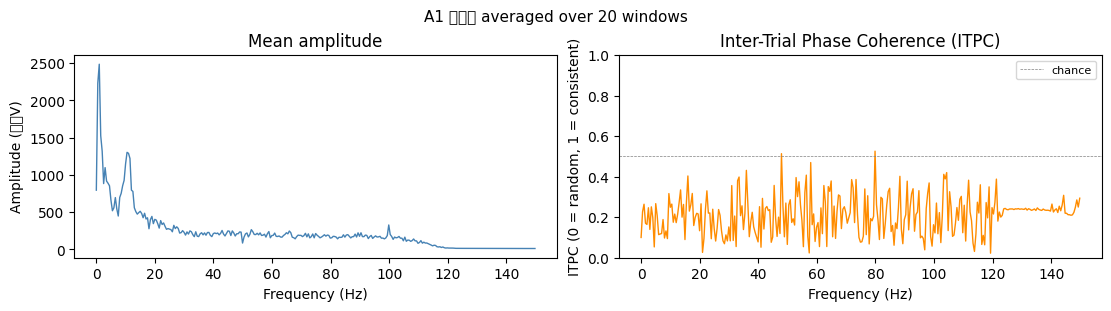

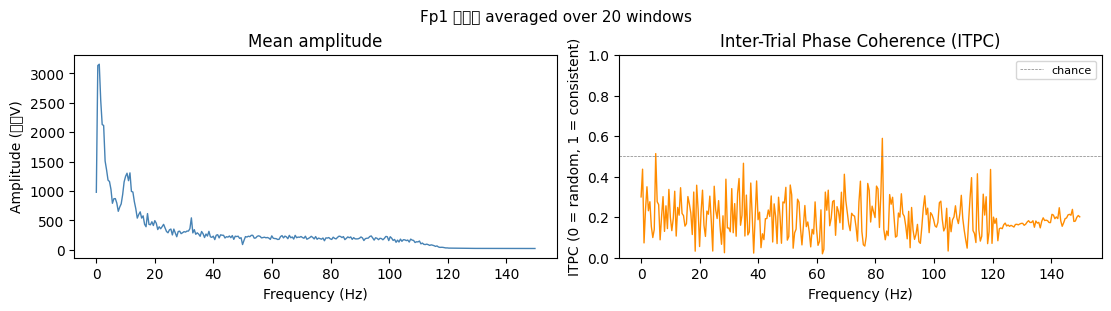

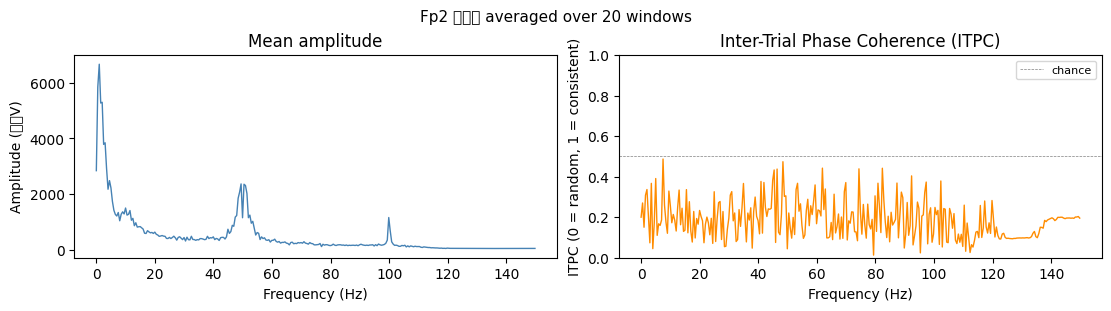

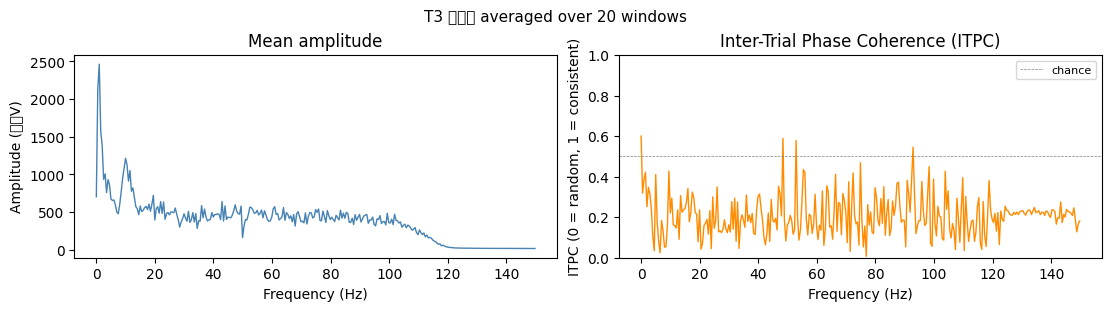

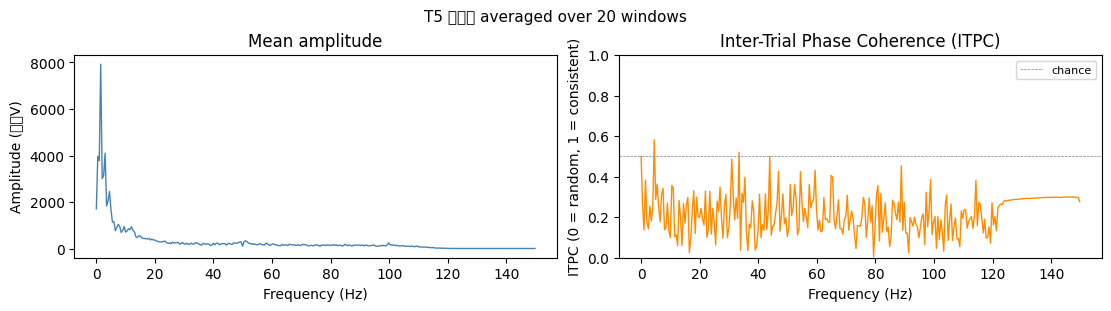

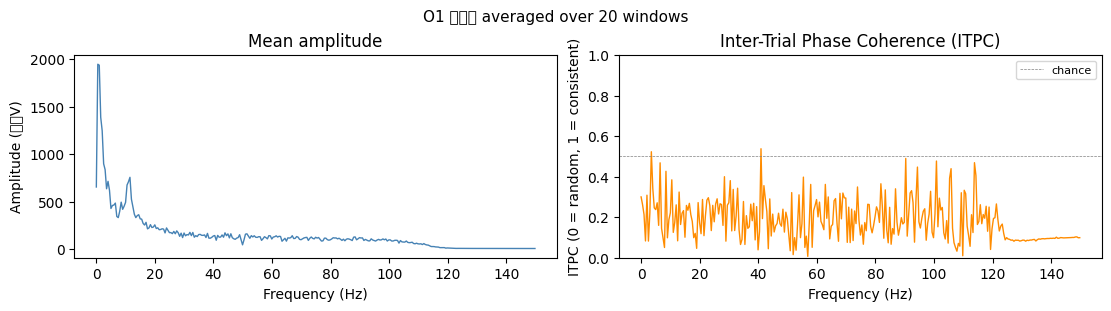

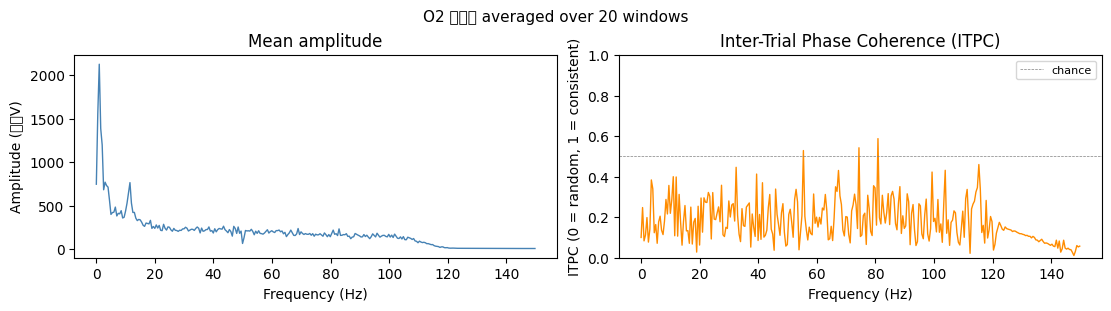

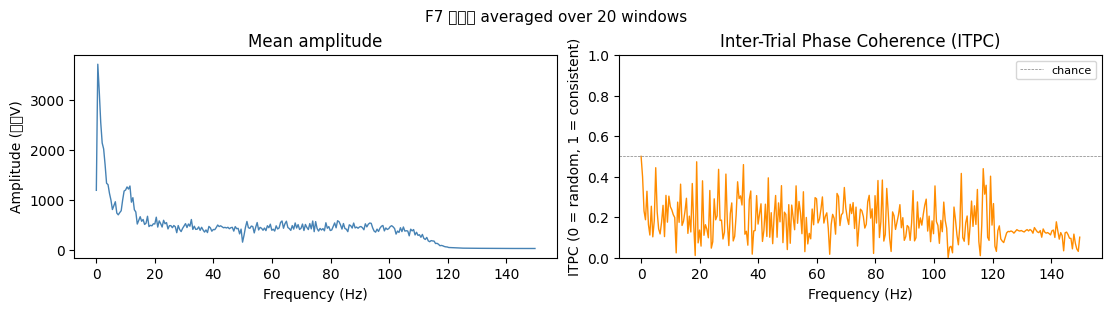

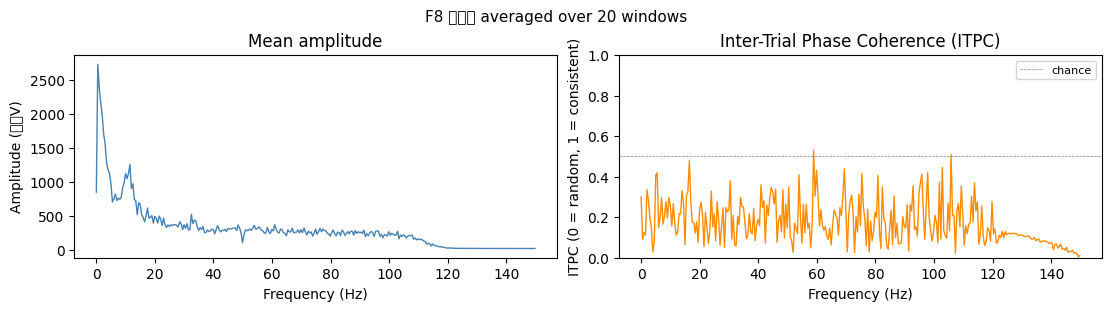

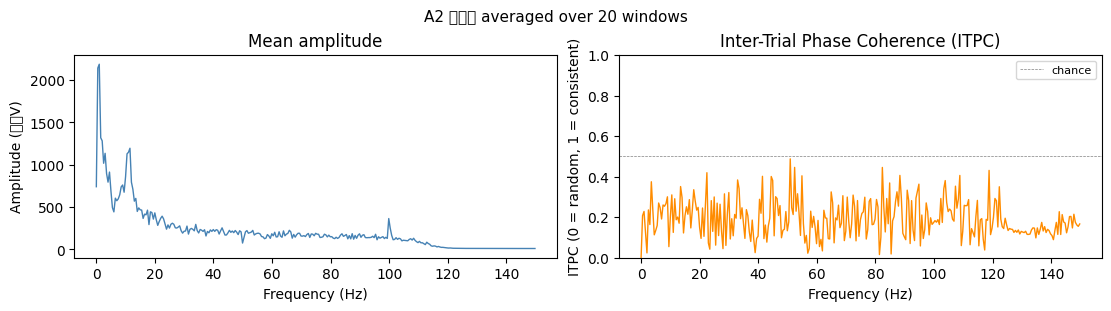

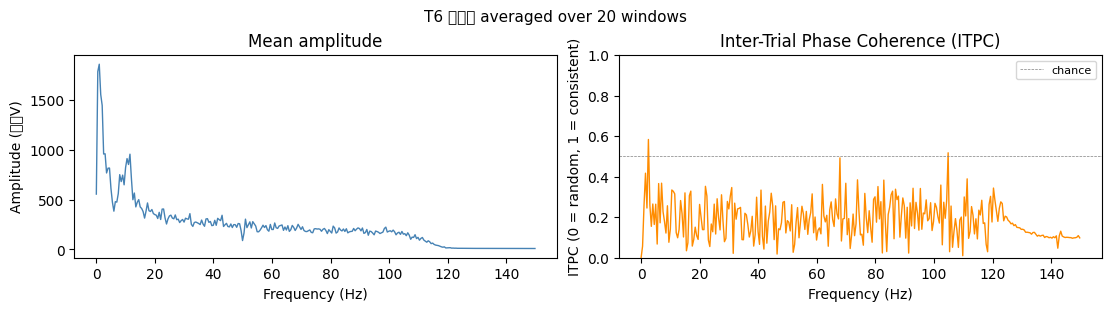

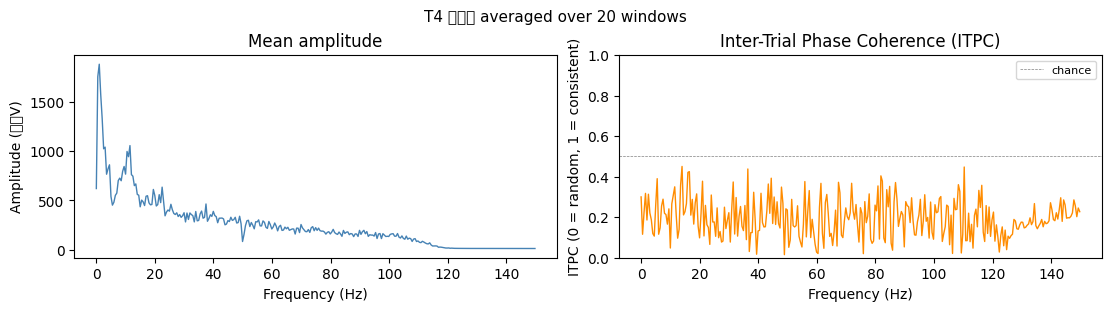

In [107]:
plot_eeg_fft(filtered_marker_eegs, eeg_freq, average_only=True)

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


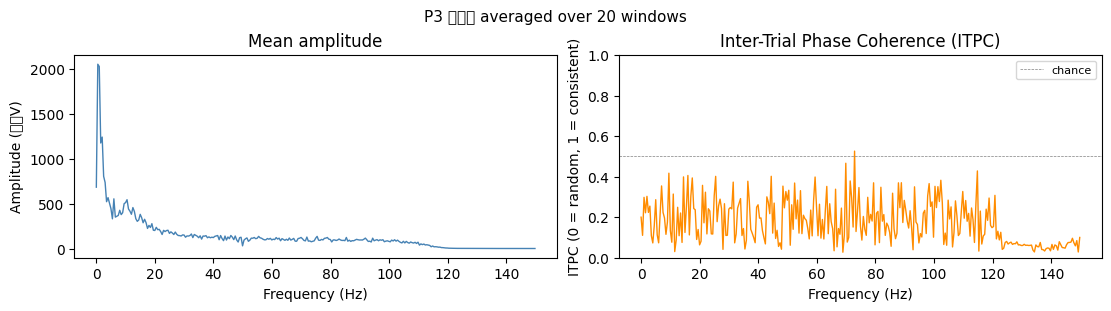

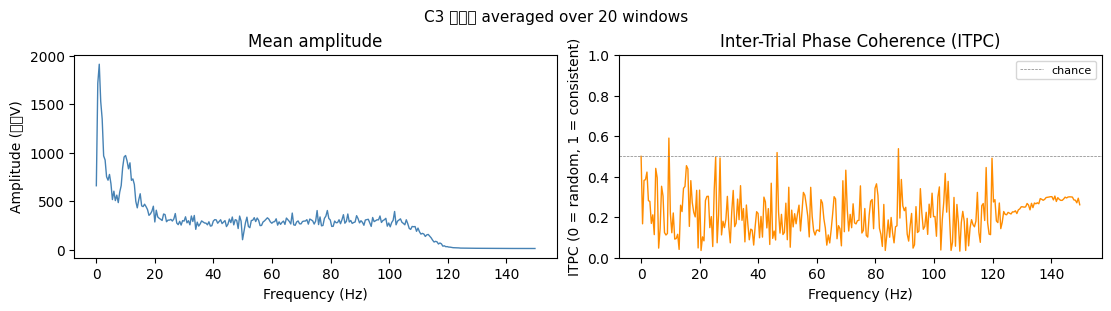

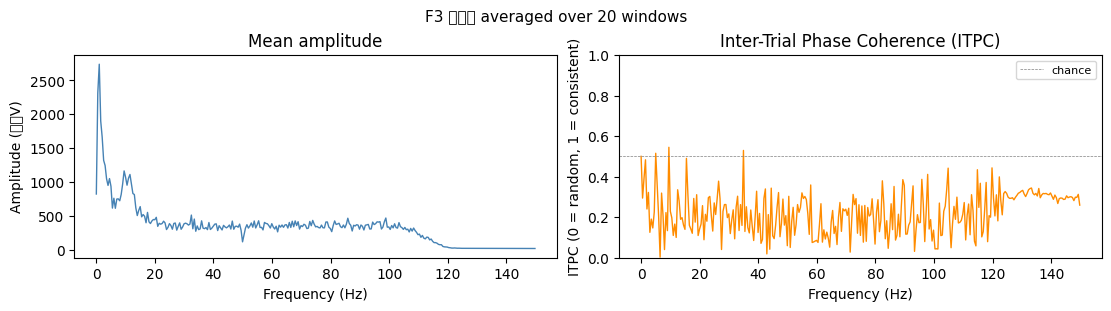

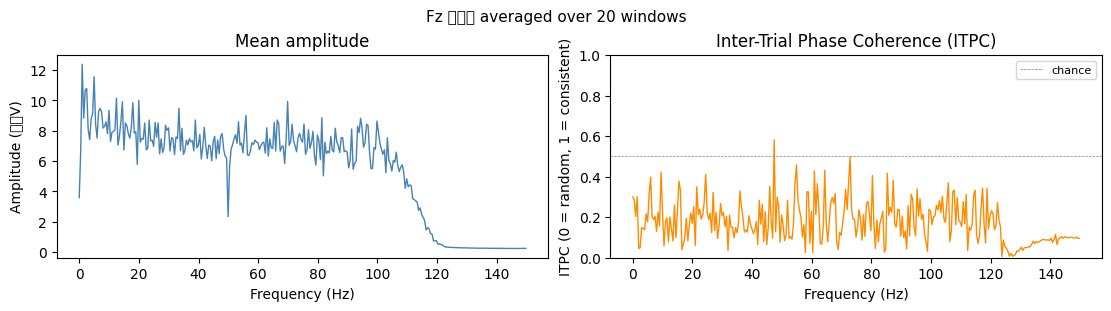

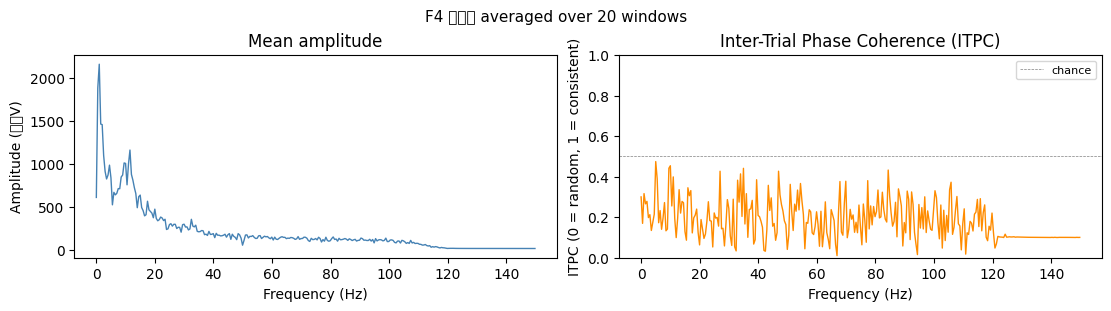

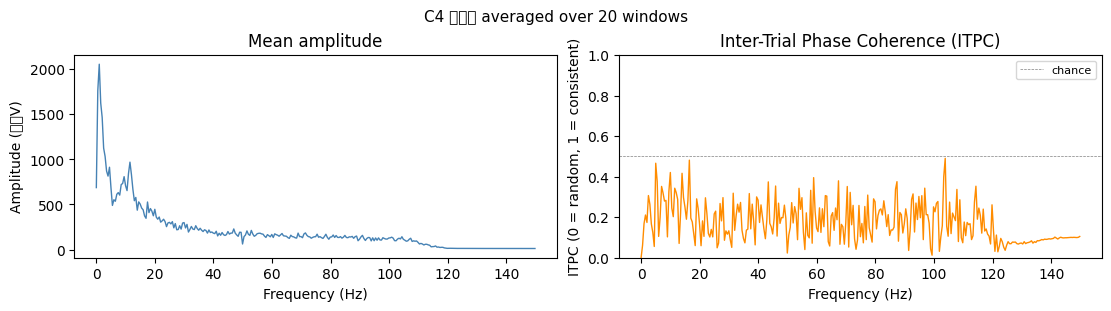

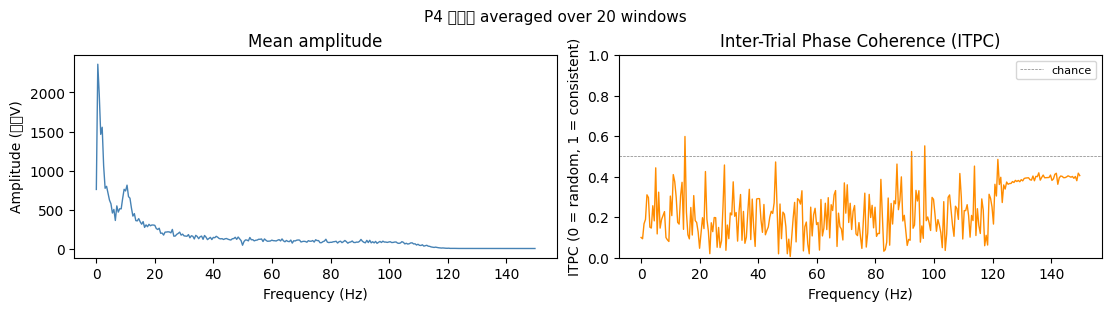

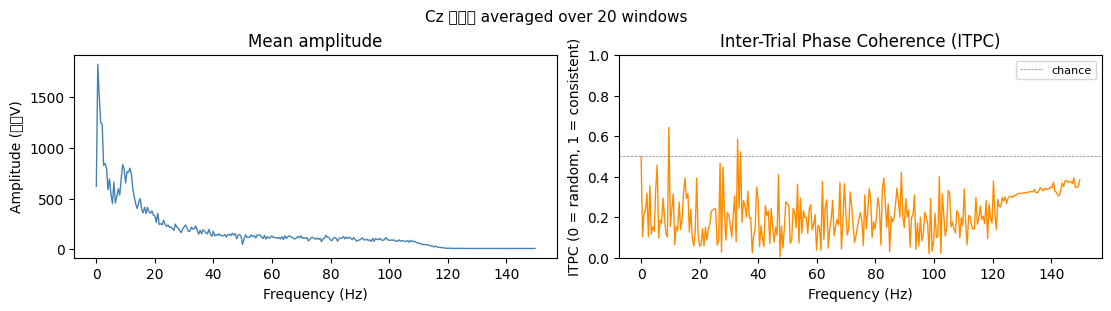

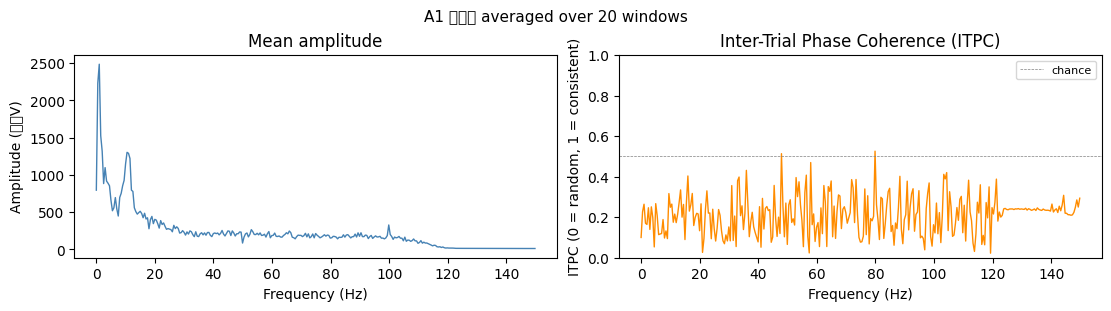

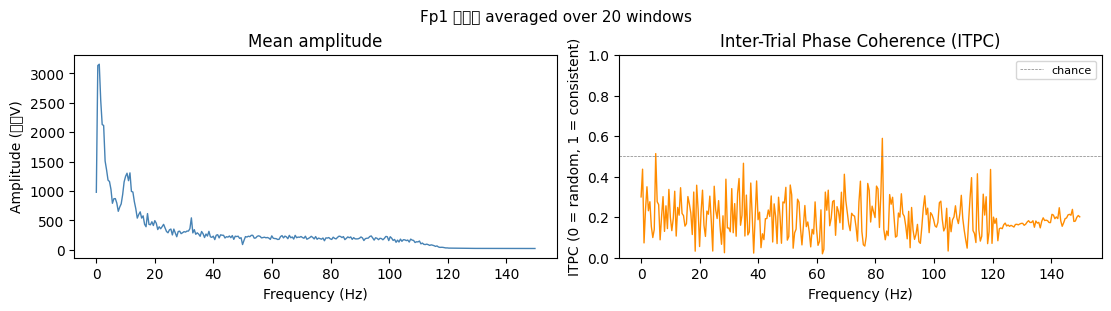

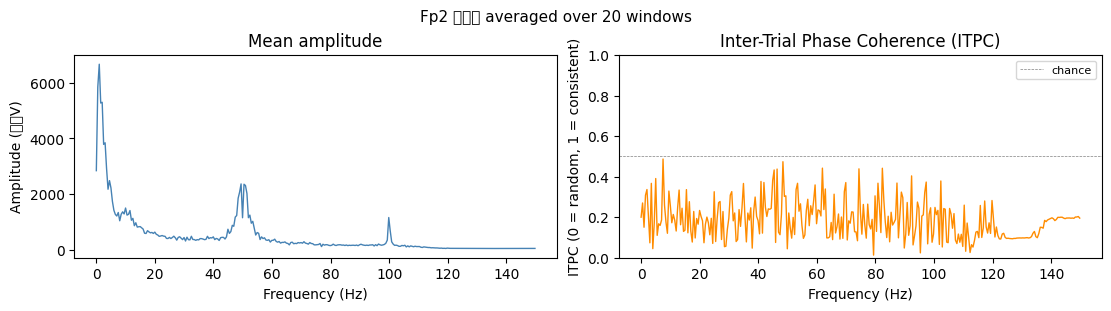

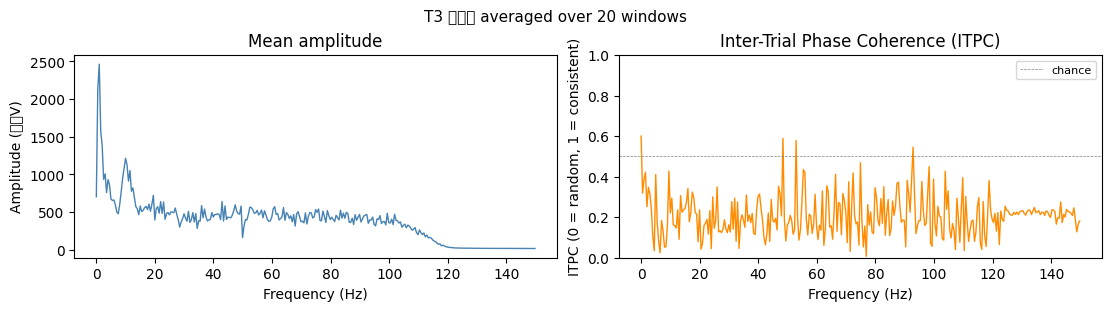

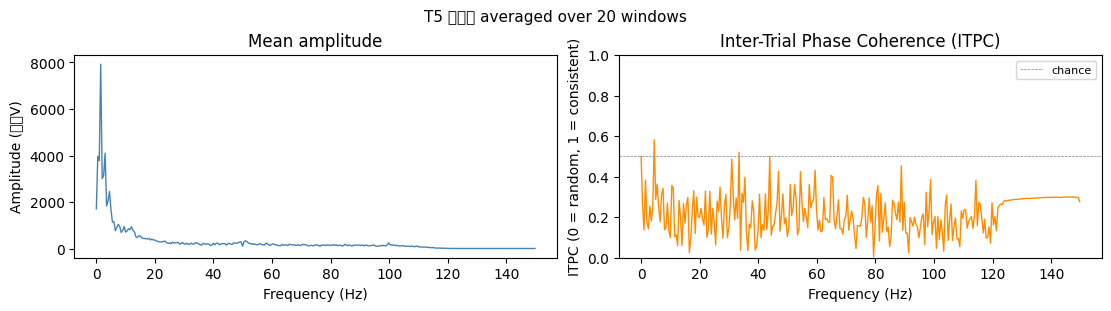

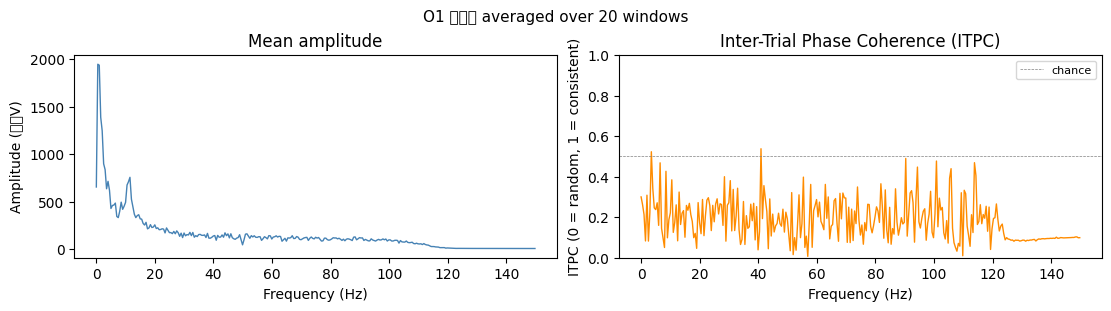

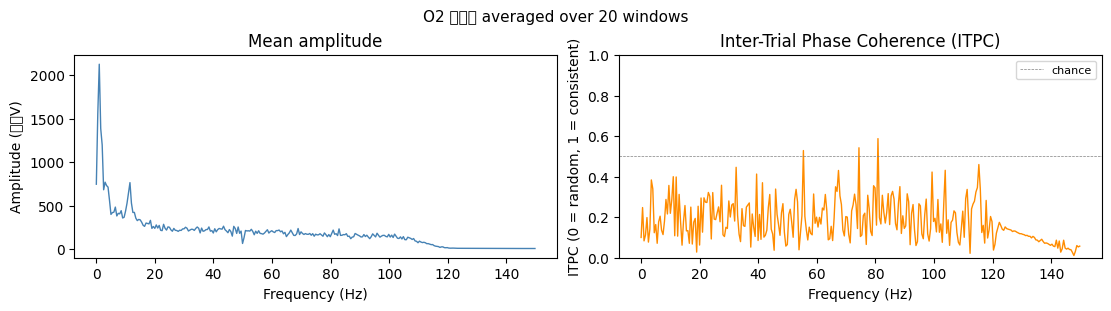

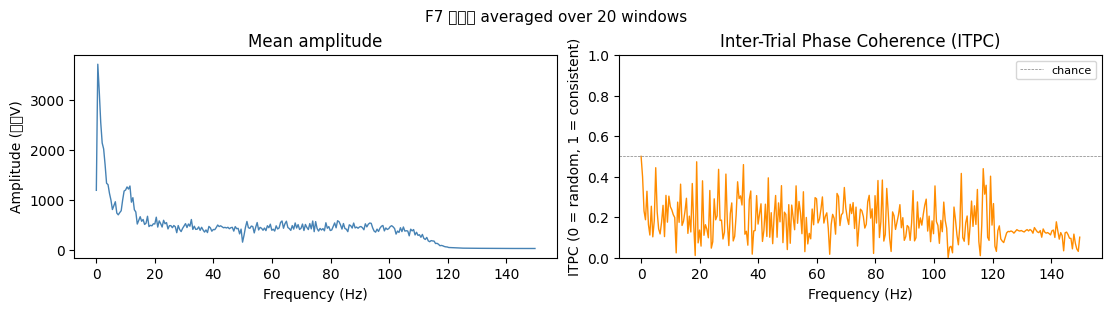

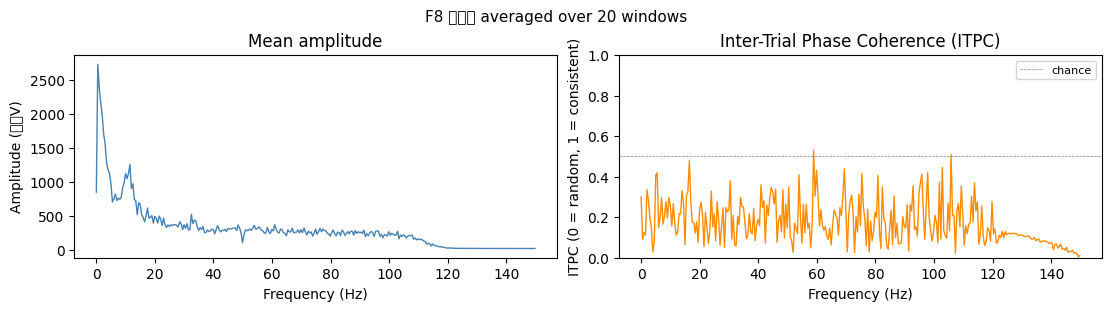

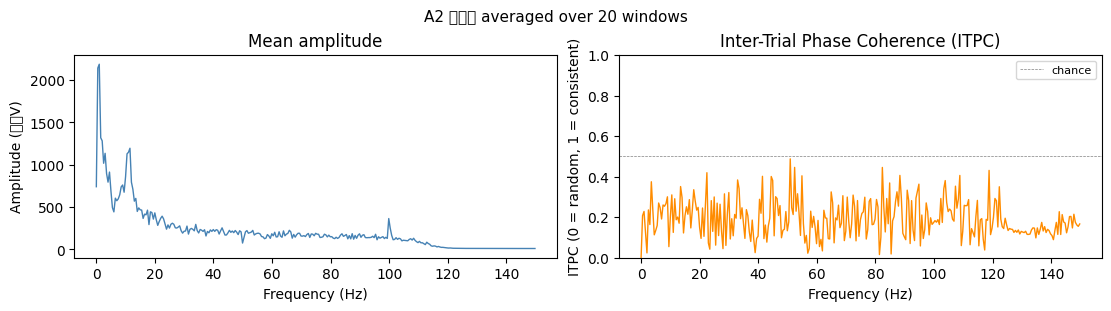

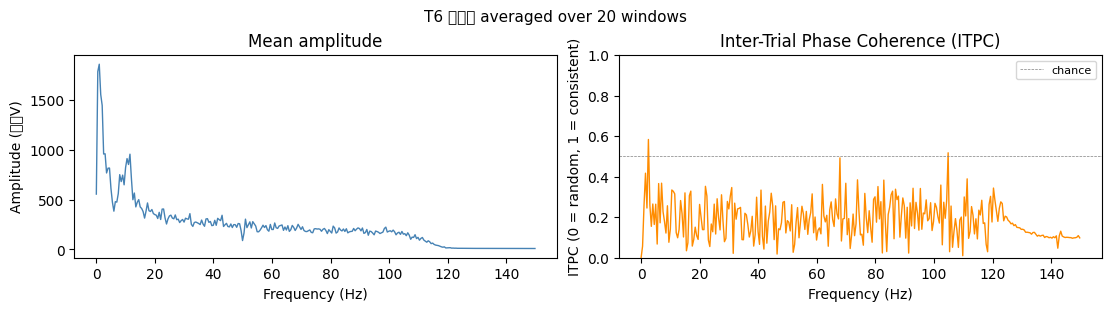

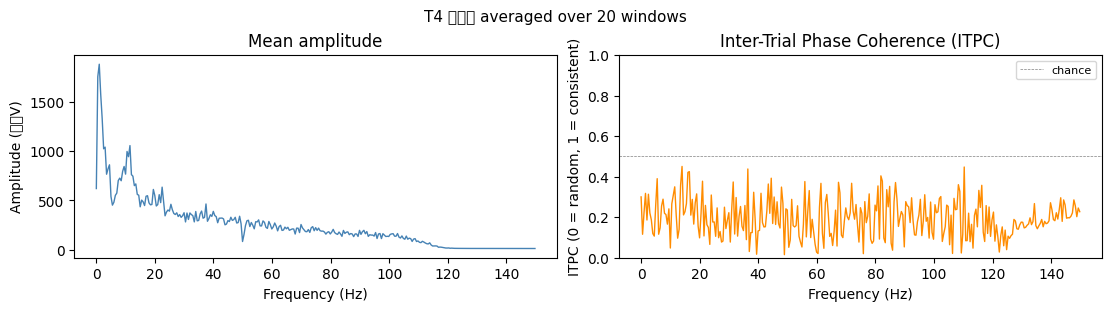

In [108]:
plot_eeg_fft(filtered_marker_eegs, eeg_freq, average_only=True)